<a href="https://colab.research.google.com/github/palakbari/Computer-Vision/blob/main/Computer_Vision.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Geometric Transformation

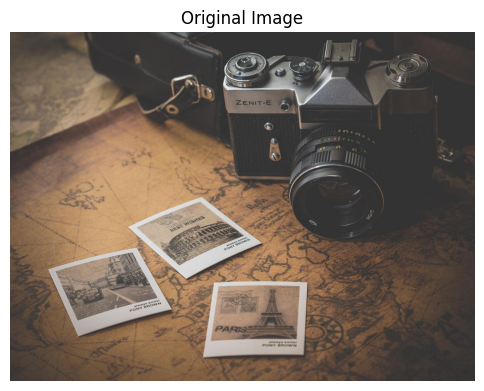

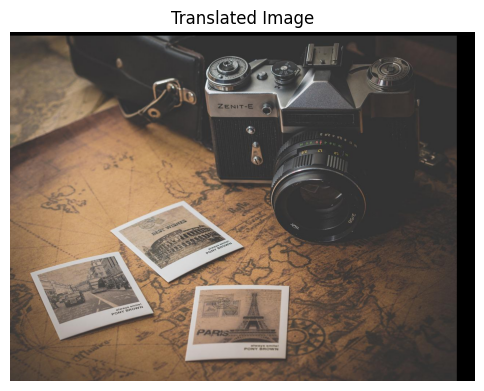

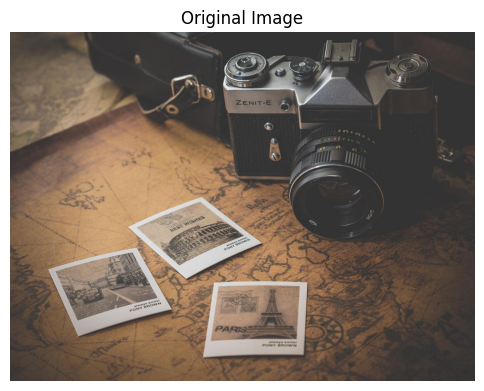

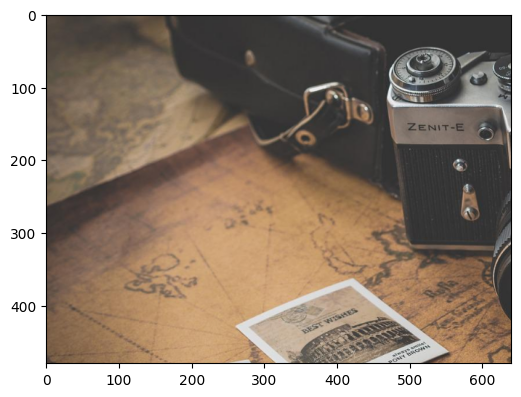

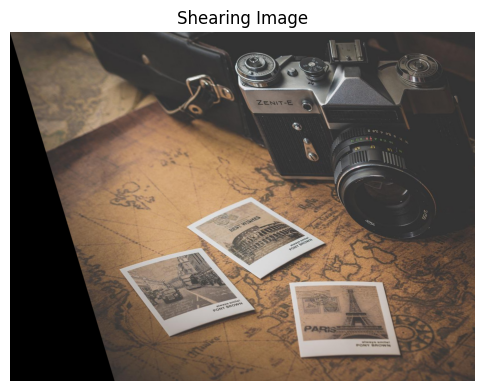

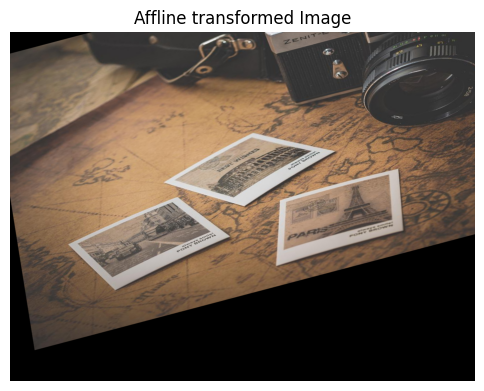

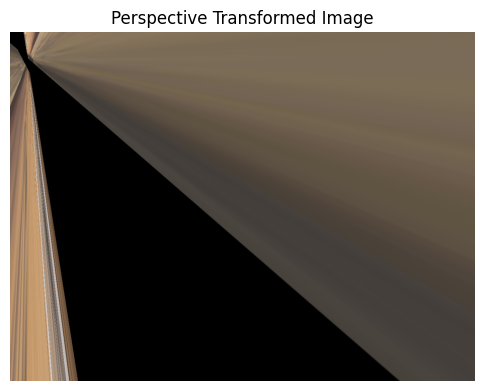

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

image= cv2.imread('image.jpg')
height, width = image.shape[:2]
plt.figure(figsize=(6,6))
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title('Original Image')
plt.axis("off")
plt.show()

#translation
translated_matrix = np.float32([[1,0,-50],[0,1,10]])#[2,0,50]
translated_image = cv2.warpAffine(image, translated_matrix, (width, height))
plt.figure(figsize=(6,6))
plt.imshow(cv2.cvtColor(translated_image, cv2.COLOR_BGR2RGB))
plt.title('Translated Image')
plt.axis("off")
plt.show()

#rotation
rotated_matrix = cv2.getRotationMatrix2D((width/2, height/2), 60, 1)
rotated_image = cv2.warpAffine(image, rotated_matrix, (width, height))
plt.figure(figsize=(6,6))
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title('Original Image')
plt.axis("off")
plt.show()

#scaling
scaling_matrix = np.float32([[0.8,0,0],[0,0.8,0]])
scaled_image = cv2.warpAffine(image, scaling_matrix, (int(width*0.5), int(height*0.5)))
plt.figure(figsize=(6,6))
plt.imshow(cv2.cvtColor(scaled_image, cv2.COLOR_BGR2RGB))

#shearing
shear_x = 0.3   # shearing factor
shearing_matrix = np.float32([[1, shear_x, 0], [0, 1, 0]])
sheared_image = cv2.warpAffine(image, shearing_matrix, (width, height))
plt.figure(figsize=(6,6))
plt.imshow(cv2.cvtColor(sheared_image, cv2.COLOR_BGR2RGB))
plt.title('Shearing Image')
plt.axis("off")
plt.show()

#affine transformation
orignal_points = np.float32([[50,50],[200,50],[100,250]])
transformed_points = np.float32([[10,100],[200,50],[100,250]])
affline_matrix = cv2.getAffineTransform(orignal_points, transformed_points)
affline_tranformed_image= cv2.warpAffine(image, affline_matrix, (width, height))
plt.figure(figsize=(6,6))
plt.imshow(cv2.cvtColor(affline_tranformed_image, cv2.COLOR_BGR2RGB))
plt.title('Affline transformed Image')
plt.axis("off")
plt.show()

#perspective transformation
orignal_points = np.float32([[56,65],[368, 52], [28,387], [389, 390]])
transformed_points = np.float32([[0,50],[55, 75], [45,100], [50, 50]])
perspective_matrix = cv2.getPerspectiveTransform(orignal_points, transformed_points)
perspective_transformed_image = cv2.warpPerspective(image, perspective_matrix, (width, height))
plt.figure(figsize=(6,6))
plt.imshow(cv2.cvtColor(perspective_transformed_image, cv2.COLOR_BGR2RGB))
plt.title('Perspective Transformed Image')
plt.axis("off")
plt.show()

# Image Stitching

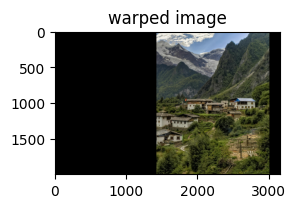

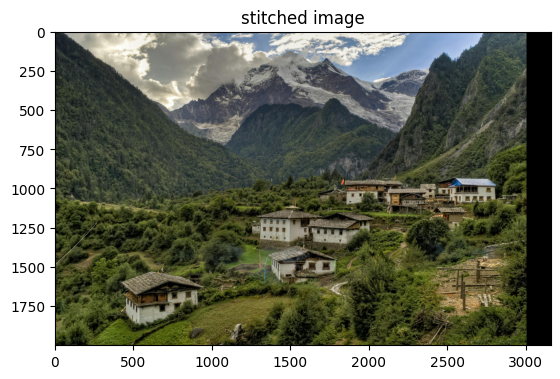

In [6]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img_=cv2.imread('right.jpg')
img1=cv2.cvtColor(img_,cv2.COLOR_BGR2GRAY)
img=cv2.imread('left.jpg')
img2=cv2.cvtColor(img,cv2.COLOR_BGR2GRAY)

sift=cv2.SIFT_create()

kp1,des1=sift.detectAndCompute(img1,None)
kp2,des2=sift.detectAndCompute(img2,None)

bf=cv2.BFMatcher(cv2.NORM_L2,crossCheck=False)
matches=bf.knnMatch(des1,des2,k=2)

good=[]
for m,n in matches:
    if m.distance<0.75 * n.distance:
        good.append(m)

if len(good)>4:

  #point extraction
  src_points=np.float32([kp1[m.queryIdx].pt for m in good]).reshape(-1,1,2)
  dst_points=np.float32([kp2[m.trainIdx].pt for m in good]).reshape(-1,1,2)

  #homography estimation
  H,status=cv2.findHomography(src_points,dst_points,cv2.RANSAC,5.0)

  #image warping
  dst=cv2.warpPerspective(img_,H,(img.shape[1]+ img_.shape[1],img.shape[0]))
  dst_rgb=cv2.cvtColor(dst,cv2.COLOR_BGR2RGB)

  #show warped image
  plt.subplot(122),plt.imshow(dst_rgb),plt.title('warped image')
  plt.show()

  #stitching

  dst[0:img.shape[0],0:img.shape[1]]=img
  combined_rgb=cv2.cvtColor(dst,cv2.COLOR_BGR2RGB)

  cv2.imwrite('output.jpg',dst)

  plt.imshow(combined_rgb)
  plt.title('stitched image')
  plt.show()

else:
  raise AssertionError("Not enough matches found - {}/{}".format(len(good),4))

# Camera Calibartion

Error: Not enough valid points for camera calibration. Check image loading and corner detection.


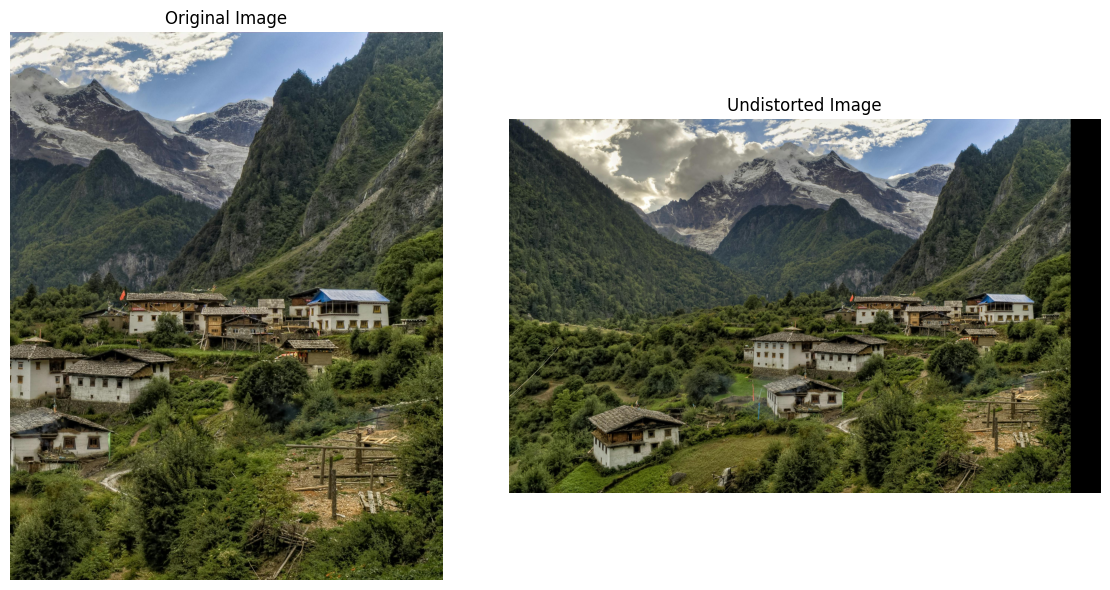

In [8]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 30, 0.001)

objp = np.zeros((6*7,3), np.float32)
objp[:,:2] = np.mgrid[0:7,0:6].T.reshape(-1,2)

objpoints = []
imgpoints = []

calibartion_images = ['left.jpg', 'image.jpg', 'right.jpg']

img_size = None
for fname in calibartion_images:
    img = cv2.imread(fname)
    if img is None:
        print(f"Warning: Could not load {fname}")
        continue

    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    if img_size is None: # Capture image size from the first loaded image
        img_size = gray.shape[::-1]

    ret, corners = cv2.findChessboardCorners(gray, (7,6), cv2.CALIB_CB_ADAPTIVE_THRESH)

    if ret == True:
        objpoints.append(objp)
        corners2 = cv2.cornerSubPix(gray, corners, (11,11), (-1,-1), criteria)
        imgpoints.append(corners2)
    else:
        print(f"Warning: Could not find chessboard corners in {fname}")


if objpoints and imgpoints and img_size:
    ret, mtx, dist, rvecs, tvecs = cv2.calibrateCamera(objpoints, imgpoints, img_size, None, None)
    print("Camera calibration successful!")
    print("Camera Matrix:")
    print(mtx)
    print("\nDistortion Coefficients:")
    print(dist)

    # Undistort the last processed image using the calibration results
    h, w = gray.shape[:2]
    newcameramtx, roi = cv2.getOptimalNewCameraMatrix(mtx, dist, (w, h), 1, (w, h))
    dst = cv2.undistort(img, mtx, dist, None, newcameramtx)

    # Crop the image based on ROI
    x, y, w_roi, h_roi = roi
    if w_roi > 0 and h_roi > 0:
        dst = dst[y:y+h_roi, x:x+w_roi]
else:
    print("Error: Not enough valid points for camera calibration. Check image loading and corner detection.")

if 'img' in locals() and img is not None and 'dst' in locals() and dst is not None:
    fig, ax = plt.subplots(1, 2, figsize=(12, 6))

    ax[0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax[0].set_title('Original Image')
    ax[0].axis('off')

    ax[1].imshow(cv2.cvtColor(dst, cv2.COLOR_BGR2RGB))
    ax[1].set_title('Undistorted Image')
    ax[1].axis('off')

    plt.tight_layout()
    plt.show()
else:
    print("Error: Original or undistorted image not available for display.")

# Face Detection

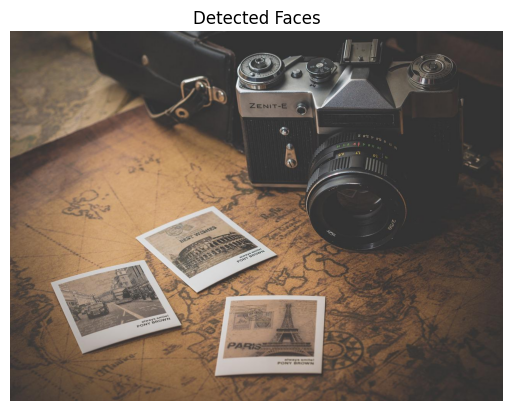

Number of faces detected: 0


In [4]:
import cv2
import os
import matplotlib.pyplot as plt

try:
    import face_recognition
    use_face_rec = True
except ImportError:
    use_face_rec = False

# Load input image from fallback
frame = None
if os.path.exists('image.jpg'):
    frame = cv2.imread('image.jpg')

if frame is not None:
    if use_face_rec:
        # Convert image to RGB for face_recognition
        rgb_frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

        # Find all face locations
        face_locations = face_recognition.face_locations(rgb_frame)

        # Draw bounding boxes
        for (top, right, bottom, left) in face_locations:
            cv2.rectangle(frame, (left, top), (right, bottom), (0, 255, 0), 2)

        num_faces = len(face_locations)
    else:
        # Fallback if face_recognition is not available
        num_faces = 0
        print("face_recognition library is not available.")

    # Display result
    plt.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
    plt.title('Detected Faces')
    plt.axis('off')
    plt.show()

    print("Number of faces detected:", num_faces)
else:
    print("Error: 'image.jpg' not found. Please upload 'image.jpg' to run detection.")

# Face Recognition

In [6]:
import face_recognition
from matplotlib import pyplot as plt
import matplotlib.patches as patches

#load known image
known_image = face_recognition.load_image_file('image.jpg')

#generate face encodings safely
known_face_encodings = face_recognition.face_encodings(known_image)
if len(known_face_encodings) == 0:
    print("Error: No faces were detected in the known image 'left.jpg'. Please use an image that contains a clear face.")
else:
    known_face_encoding = known_face_encodings[0]

    #load unknown image
    unknown_image = face_recognition.load_image_file('image.jpg')

    #detect faces in unknown image first to get locations
    unknown_face_locations = face_recognition.face_locations(unknown_image)
    unknown_face_encodings = face_recognition.face_encodings(unknown_image, unknown_face_locations)

    #convert image from BGR -> RGB
    unknown_image_rgb = unknown_image

    #create figure for display
    fig, ax = plt.subplots(1, 1, figsize=(8, 6))
    ax.imshow(unknown_image_rgb)

    if len(unknown_face_locations) == 0:
        print("No faces detected in the unknown image 'image.jpg'.")
    else:
        #compare each detected face
        for (top, right, bottom, left), unknown_face_encoding in zip(unknown_face_locations, unknown_face_encodings):
            results = face_recognition.compare_faces([known_face_encoding], unknown_face_encoding)

            if results[0]:
                name = 'Known Person'
            else:
                name = 'Unknown Person'

            #draw rectangle around face
            ax.add_patch(patches.Rectangle((left, top), right-left, bottom-top, fill=False, color='red', linewidth=2))

            #display name below the box
            ax.text(left + 6, bottom + 25, name, color='white', fontsize=12, bbox=dict(facecolor='red', alpha=0.5, edgecolor='white'))

    #finalize display
    plt.title("Face Recognition")
    plt.axis('off')
    plt.show()

    #end message
    print("Program Executed Successfully")

Error: No faces were detected in the known image 'left.jpg'. Please use an image that contains a clear face.


# Object Detection

In [ ]:
import cv2
import argparse
import numpy as np
import matplotlib.pyplot as plt

#define model
args = argparse.Namespace(image = "image.jpg", config = "yolov3.cfg", weights = "yolov3.weights", classes = "yolov3.txt")

#output layer
def get_output_layers(net):
  layer_names = net.getLayerNames()
  try:
    output_layers = [layer_names[i - 1] for i in net.getUnconnectedOutLayers()]
  except:
    output_layers = [layer_names[i[0] - 1] for i in net.getUnconnectedOutLayers()]
  return output_layers

#prediction layer
def draw_prediction(img, class_id, confidence, x, y, x_plus_w, y_plus_h):
  label = str(classes[class_id])
  color = COLORS[class_id]
  cv2.rectangle(img, (x,y), (x_plus_w,y_plus_h), color, 2)
  cv2.putText(img, label, (x-10,y-10), cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 2)

#read input image
image = cv2.imread(args.image)
Height, Width = image.shape[:2]

#load class label
with open(args.classes, 'r') as f:
  classes = [line.strip() for line in f.readlines()]

COLORS = np.random.uniform(0, 255, size=(len(classes), 3))

#load yolo model
net = cv2.dnn.readNet(args.weights, args.config)

#pre processing the image into a blob
blob = cv2.dnn.blobFromImage(image, 0.00392, (416,416), (0,0,0), True, crop=False)
net.setInput(blob)

#forward pass
outs = net.forward(get_output_layers(net))

#prepare lists to hold detection data
class_ids = []
confidences = []
boxes = []

conf_threshold = 0.5
nms_threshold = 0.4

#parse the network output
for out in outs:
  for detection in out:
    scores = detection[5:]
    class_id = np.argmax(scores)
    confidence = scores[class_id]

    if confidence > conf_threshold:
      center_x = int(detection[0] * Width)
      center_y = int(detection[1] * Height)
      w = int(detection[2] * Width)
      h = int(detection[3] * Height)
      x = center_x - w / 2
      y = center_y - h / 2

      class_ids.append(class_id)
      confidences.append(float(confidence))
      boxes.append([x, y, w, h])

#apply non-maximum suppression
indices = cv2.dnn.NMSBoxes(boxes, confidences, conf_threshold, nms_threshold)

#final bounding boxes
for i in indices:
  try:
    box = boxes[i]
  except:
    i = i[0]
    box = boxes[i]
  x, y, w, h = box
  draw_prediction(image, class_ids[i], confidences[i], round(x), round(y), round(x+w), round(y+h))

#annotated image
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title('Detected Objects')
plt.axis('off')
plt.show()

#save the result
cv2.imwrite("object-detection.jpg", image)

#end message
print("Program Executed Successfully")


# Pedistrian Detection

In [ ]:

import cv2
import matplotlib.pyplot as plt

#load pre-trained Haar Cascade Model
pedestrain_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_fullbody.xml')

#load input video
video_path = 'traffic.mp4'
cap = cv2.VideoCapture(video_path)

#check if video opened successfully
if not cap.isOpened():
    print("Error: Could not open video.")
    exit()

#read frames continuously
while True:
  ret, frame = cap.read()
  if not ret:
    break

#convert frame to GrayScale
gray_frame = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

#detect pedestrians
pedestrians = pedestrain_cascade.detectMultiScale(gray_frame, scaleFactor=1.1, minNeighbors=5, minSize=(30, 30))

#draw boundary box
for (x, y, w, h) in pedestrians:
  cv2.rectangle(frame, (x, y), (x+w, y+h), (0, 255, 0), 2)

#display each processed frame
plt.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
plt.title('Processed Frame')
plt.axis('off')
plt.show()

#release the video resourse
cap.release()

#end message
print("Program Executed Successfully")